# 02. Logistic Regression on Real Data

**Goals.** By the end you can:

- carry out the full **real-data workflow**: **load → look → split → scale → fit → evaluate →
  interpret**;
- use two new tools: `train_test_split` (making a test set) and `StandardScaler` (putting features on
  a common scale), and say why the scaler is fitted on the training data only;
- choose a decision threshold honestly, **on your own**.

**Part A** (together): the whole workflow on a dataset of banknotes, genuine vs. forged.
**Part B** (on your own, then together): the same workflow on a **medical** dataset, diagnosing breast
tumors.

**Estimated time:** about 80 minutes.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Interactive sliders (optional): if ipywidgets is missing, we show a few fixed pictures instead.
try:
    from ipywidgets import interact, FloatSlider, FloatLogSlider
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print("ipywidgets is not installed: the interactive cells will show fixed pictures instead.")

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, precision_score, recall_score)

In [2]:
# --- exercise checker: just run this cell -----------------------------------------------
import base64 as _b64, json as _json
_ANS = _json.loads(_b64.b64decode("eyJXMSI6IFswLjgsIDAuNjY2NjY2NjY2NjY2NjY2Nl0sICJXMiI6IDAuMiwgIlczIjogMi4wMTM3NTI3MDc0NzA0NzY2LCAiQSsxIjogWzEzNzIsIDAuNDQ0NjA2NDEzOTk0MTY5MV0sICJBKzMiOiBbOTYwLCA0MTIsIDAuNDQ0NzkxNjY2NjY2NjY2NjQsIDAuNDQ0MTc0NzU3MjgxNTUzNF0sICJBMyI6IC0wLjcwMDI4OTM0NzgyOTM3OTMsICJCMSBzcGxpdCI6IFszOTgsIDE3MSwgMC4zNzE4NTkyOTY0ODI0MTIwNiwgMC4zNzQyNjkwMDU4NDc5NTMyXSwgIkIxIHNjYWxlIjogWzAuMCwgMS4wXSwgIkIyIjogWzAuOTcwNzYwMjMzOTE4MTI4NiwgNjAsIDEsIDQsIDEwNl0sICJCNCI6IFtbIndvcnN0IHRleHR1cmUiLCAicmFkaXVzIGVycm9yIiwgIndvcnN0IHN5bW1ldHJ5Il0sIFsiY29tcGFjdG5lc3MgZXJyb3IiLCAiZnJhY3RhbCBkaW1lbnNpb24gZXJyb3IiLCAibWVhbiBjb21wYWN0bmVzcyJdXSwgIk9uIHlvdXIgb3duOiB0aHJlc2hvbGQiOiAwLjIsICJPbiB5b3VyIG93bjogdGVzdCI6IFswLjk4NDM3NSwgMC45NTQ1NDU0NTQ1NDU0NTQ2XX0="))

def _has_str(v):
    return isinstance(v, str) or (isinstance(v, (list, tuple)) and any(_has_str(x) for x in v))

def _norm(v):
    return [_norm(x) for x in v] if isinstance(v, (list, tuple, np.ndarray)) else str(v).strip().lower()

def _close(a, b, tol):
    if _has_str(b):
        return _norm(a) == _norm(b)
    try:
        return np.allclose(np.asarray(a, dtype=float), np.asarray(b, dtype=float), atol=tol, rtol=0)
    except Exception:
        return False

def check(key, value, tol=1e-3):
    # Compare your answer for exercise `key` with the expected one.
    if value is None or value is Ellipsis or (isinstance(value, (list, tuple)) and any(v is None for v in value)):
        print(f"⏳ {key}: not answered yet")
    elif _close(value, _ANS[key], tol):
        print(f"✅ {key}: correct!")
    else:
        print(f"❌ {key}: not yet. You got {value}; check your work and try again")

def check_against(key, value, reference, tol=1e-3):
    # Compare your answer with a reference value computed in the same cell.
    if value is None or (isinstance(value, (list, tuple)) and any(v is None for v in value)):
        print(f"⏳ {key}: not answered yet")
    elif _close(value, reference, tol):
        print(f"✅ {key}: correct!")
    else:
        print(f"❌ {key}: not yet. You got {value}; check your work and try again")

def check_fn(key, fn, tol=1e-3):
    # Call your function on some test inputs and compare with the expected outputs.
    spec = _ANS[key]
    try:
        outs = [fn(*[np.array(a, dtype=float) for a in args]) for args in spec["args"]]
    except Exception as e:
        print(f"❌ {key}: your function raised an error: {type(e).__name__}: {e}")
        return
    if any(o is None for o in outs):
        print(f"⏳ {key}: not answered yet (your function returns None)")
    elif all(_close(o, ex, tol) for o, ex in zip(outs, spec["out"])):
        print(f"✅ {key}: correct!")
    else:
        print(f"❌ {key}: not yet. Your function gives {outs}; check your work and try again")

## Warm-up: 01b and 01c in two questions

**W1.** A classifier's confusion matrix has TP = 40, FP = 10, FN = 20, TN = 130. What are its precision
and recall? Store them in `w1_answer = [precision, recall]`.

**W2.** A false positive costs 1 and a false negative costs 4. What is the best threshold? (Recall from
01c: $t^* = \frac{\text{cost}_{FP}}{\text{cost}_{FP} + \text{cost}_{FN}}$.) Store it in `w2_answer`.

In [3]:
TP = 40
FP = 10
FN = 20
TN = 130
w1_answer = [(TP)/(TP + FP), (TP)/(TP + FN)]
w2_answer = 1/(1 + 4)
check("W1", w1_answer)
check("W2", w2_answer)

✅ W1: correct!
✅ W2: correct!


# Part A: banknotes, together

Banks and shops need to detect **forged banknotes**. In this dataset (UCI Machine Learning Repository),
each example is a photo of a banknote-like specimen, genuine or forged. Four numbers were computed from
each image: `variance`, `skewness`, `curtosis` and `entropy` (statistics of the image after a
*wavelet transform*). The label is 0 or 1; it's commonly assumed that **1 = forged**, and we'll go with
that. (A real-data surprise: the dataset's documentation doesn't say!)

**Source:** V. Lohweg (2012), *Banknote Authentication*, UCI Machine Learning Repository,
[doi:10.24432/C55P57](https://doi.org/10.24432/C55P57), licensed CC BY 4.0.

## A1. Load and look

Real datasets usually come as tables in files, and we read them with **pandas**. The few commands we
need (a table is a **DataFrame**, like a 2D NumPy array with named columns):

- `pd.read_csv(path)` reads a table from a file;
- `df.head()` shows the first rows, `df.describe()` summary statistics of every column;
- `df["column"]` picks a column, and `.values` turns a table or a column into a NumPy array.

In [4]:
cols = ["variance", "skewness", "curtosis", "entropy", "label"]
bank = pd.read_csv("./data/data_banknote_authentication.txt", header=None, names=cols)
X_bank = bank[["variance", "skewness", "curtosis", "entropy"]].values
y_bank = bank["label"].values
names_bank = ["variance", "skewness", "curtosis", "entropy"]
bank.describe().round(2)

,variance,skewness,curtosis,entropy,label
count,1372.00,1372.00,1372.00,1372.00,1372.00
mean,0.43,1.92,1.40,-1.19,0.44
std,2.84,5.87,4.31,2.10,0.50
min,-7.04,-13.77,-5.29,-8.55,0.00
25%,-1.77,-1.71,-1.57,-2.41,0.00
50%,0.50,2.32,0.62,-0.59,0.00
75%,2.82,6.81,3.18,0.39,1.00
max,6.82,12.95,17.93,2.45,1.00


`describe()` shows, for every column: the count, mean, standard deviation (`std`), minimum,
quartiles and maximum. Notice that the four features have **different ranges**: `curtosis` goes up to
about 17, while `entropy` stays between about $-8.5$ and $2.5$. We'll come back to this in A3.

## A2. Split into training and test sets

In 01b we generated a fresh test set. With real data we can't: we have **one** dataset. So we split it
ourselves: we **hide** part of it (the test set), train only on the rest, and evaluate on the hidden
part at the end. That simulates new, unseen data. `train_test_split` does this in one line:

- `test_size=0.3` puts 30% of the examples in the test set;
- `stratify=y` keeps the **same class balance** in both parts;
- `random_state=0` fixes the randomness, so we all get the same split.

In [5]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bank, y_bank, test_size=0.3, stratify=y_bank, random_state=0)

print("training set:", X_train_b.shape, "   test set:", X_test_b.shape)

training set: (960, 4)    test set: (412, 4)


## A3. Scale the features

The four features live on different scales. We **standardize** each one: subtract its mean and divide
by its standard deviation,

$$x_j^{\text{scaled}} = \frac{x_j - \text{mean}_j}{\text{std}_j},$$

so every feature gets mean 0 and standard deviation 1. `StandardScaler` does it in two steps:
`.fit(X)` **computes** the mean and standard deviation of every column, and `.transform(X)` **applies**
the formula with the stored values.

**Why scale?** (1) The optimizer that trains logistic regression converges much faster when the
features are on similar scales. (2) After scaling, all features are in the same "units", so their
**weights can be compared** (01b, exercise 5.B). *(A third reason will appear in 03b.)*

**Important: fit the scaler on the training data only.** The test set plays the role of future data.
Computing the means with the test set too would quietly use information from the "future": a small
form of cheating called **data leakage**. So we `fit` on the training data, then `transform` **both**
sets with the training means and standard deviations.

In [6]:
scaler_b = StandardScaler()
scaler_b.fit(X_train_b)                           # learn means and stds from the TRAINING data only
X_train_b_s = scaler_b.transform(X_train_b)
X_test_b_s = scaler_b.transform(X_test_b)         # the same means and stds, applied to the test data

print("scaled training data: means", X_train_b_s.mean(axis=0).round(3), "  stds", X_train_b_s.std(axis=0).round(3))
print("scaled test data:     means", X_test_b_s.mean(axis=0).round(3), "  stds", X_test_b_s.std(axis=0).round(3))

scaled training data: means [-0. -0. -0.  0.]   stds [1. 1. 1. 1.]
scaled test data:     means [-0.029  0.01   0.015 -0.123]   stds [1.04  1.028 1.028 1.106]


The scaled **training** data has means of exactly 0 and standard deviations of exactly 1; the test
data is close, but not exactly, as expected.

**Your turn (A3).** Standardize the `variance` of the **first** training banknote **by hand**, using
NumPy (`np.mean`, `np.std`) on the training data. Store it in `scaled_by_hand` and compare it with
`X_train_b_s[0, 0]`.

In [7]:
np_X_train = np.array(X_train_b)[:, 0]
scaled_by_hand = (np_X_train[0] - np.mean(np_X_train))/(np.std(np_X_train))
print("by hand:", scaled_by_hand, "   StandardScaler:", X_train_b_s[0, 0])
check("A3", scaled_by_hand)

by hand: -0.7002893478293793    StandardScaler: -0.7002893478293796
✅ A3: correct!


## A4. Fit and evaluate

In [8]:
clf_b = LogisticRegression()
clf_b.fit(X_train_b_s, y_train_b)

pred_b = clf_b.predict(X_test_b_s)
proba_b = clf_b.predict_proba(X_test_b_s)[:, 1]

print("test accuracy:", round(accuracy_score(y_test_b, pred_b), 4))
print("test AUC:     ", round(roc_auc_score(y_test_b, proba_b), 4))
print("\nconfusion matrix:\n", confusion_matrix(y_test_b, pred_b))
print()
print(classification_report(y_test_b, pred_b, target_names=["genuine (0)", "forged (1)"]))

test accuracy: 0.9927
test AUC:      1.0

confusion matrix:
 [[227   2]
 [  1 182]]

              precision    recall  f1-score   support

 genuine (0)       1.00      0.99      0.99       229
  forged (1)       0.99      0.99      0.99       183

    accuracy                           0.99       412
   macro avg       0.99      0.99      0.99       412
weighted avg       0.99      0.99      0.99       412



An excellent result: almost every test banknote is classified correctly, and the AUC is 1.0. The
banknote classes are **almost linearly separable** in these four features, the ideal situation for a
linear model. Real problems are rarely this easy; Part B is more typical.

## A5. Interpret

The features are standardized, so the weights are comparable.

variance   -4.516
skewness   -4.496
curtosis   -4.196
entropy     0.259
dtype: float64
intercept: -1.422


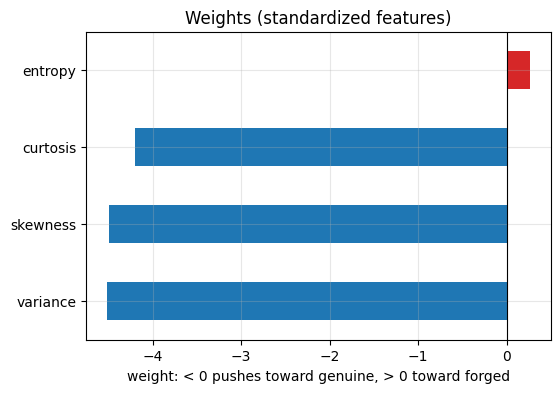

In [9]:
coef_b = pd.Series(clf_b.coef_[0], index=names_bank)
print(coef_b.round(3))
print("intercept:", clf_b.intercept_[0].round(3))

coef_b.sort_values().plot.barh(color=["tab:blue" if v < 0 else "tab:red" for v in coef_b.sort_values()])
plt.axvline(0, color="k", linewidth=0.8)
plt.title("Weights (standardized features)")
plt.xlabel("weight: < 0 pushes toward genuine, > 0 toward forged")
plt.show()

**Try it yourself, before reading on:** which feature pushes most strongly toward *genuine*? Which
feature hardly matters?

**Your answer:** *(write here)*

# Part B: breast cancer diagnosis, a guided exercise

Now it's your turn to do the whole workflow, on the **Breast Cancer Wisconsin (Diagnostic)** dataset.
Each example is a breast tumor, described by **30 measurements** computed from a microscope image of
its cells (radius, texture, perimeter, area, smoothness, and so on, each as a mean, an error, and a
"worst" value). The question: is the tumor **malignant** (cancerous) or **benign**? The data comes with
scikit-learn.

**A note about the labels.** sklearn codes this dataset as 0 = malignant, 1 = benign. For us the
"positive" class, the one we want to detect, is **malignant**, so we **flip the labels**:
`y = 1 - target` gives **1 = malignant, 0 = benign**. (Otherwise "recall" would mean "recall of benign
tumors", and every weight's sign would be flipped.)

In [22]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X_c = cancer.data
y_c = 1 - cancer.target                     # flip: 1 = malignant, 0 = benign
feature_names = list(cancer.feature_names)

print("X shape:", X_c.shape)
print("fraction malignant:", y_c.mean().round(3))

X shape: (569, 30)
fraction malignant: 0.373


### B1. Split, scale, fit

The same three steps as in A2–A4:

1. **Split** `X_c, y_c`: 30% for testing, with `stratify`, and `random_state=42`. Name the results
   `X_train_c, X_test_c, y_train_c, y_test_c`, and store
   `b1 = [n_train, n_test, fraction malignant in training, fraction malignant in test]`.
2. **Scale** with a `StandardScaler` fitted on the **training data only**. Name the results
   `X_train_c_s` and `X_test_c_s`. As a check, compute the largest absolute column mean (`max_mean`)
   and the largest column standard deviation (`max_std`) of `X_train_c_s`.
3. **Fit** a `LogisticRegression` on the scaled training data. Call it `clf_c`.

In [11]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_c, y_c, test_size=0.3, stratify=y_c, random_state=42)
b1 = [y_train_c.size, y_test_c.size, int(np.count_nonzero(y_train_c))/y_train_c.size, int(np.count_nonzero(y_test_c))/y_test_c.size]

scaler_c = StandardScaler()
scaler_c.fit(X_train_c)                           # learn means and stds from the TRAINING data only
X_train_c_s = scaler_c.transform(X_train_c)
X_test_c_s = scaler_c.transform(X_test_c)         # the same means and stds, applied to the test data

max_mean = np.max(X_train_c_s.mean(axis=0))
max_std = np.max(X_train_c_s.std(axis=0))
clf_c = LogisticRegression()
clf_c.fit(X_train_c_s, y_train_c)
print(b1)
check("B1 split", b1)
check("B1 scale", None if max_mean is None else [max_mean, max_std], tol=1e-6)

[398, 171, 0.37185929648241206, 0.3742690058479532]
✅ B1 split: correct!
✅ B1 scale: correct!


### B2. Evaluate on the test set

1. Compute the test **accuracy** and the **confusion matrix**, and print the `classification_report`.
2. Store `b2 = [accuracy, TP, FP, FN, TN]`.
3. In words: how many malignant tumors did the model **miss**? How many benign tumors did it wrongly
   call malignant? Which of these two mistakes is worse here?

In [12]:
pred_c = clf_c.predict(X_test_c_s)
proba_c = clf_c.predict_proba(X_test_c_s)[:, 1]

accuracy_c = accuracy_score(y_test_c, pred_c)
confusion_matrix_c = np.array(confusion_matrix(y_test_c, pred_c))
print(classification_report(y_test_c, pred_c, target_names=["benign (0)", "malignant (1)"]))

b2 = [accuracy_c, confusion_matrix_c[1][1], confusion_matrix_c[0][1], confusion_matrix_c[1][0], confusion_matrix_c[0][0]]
print(b2)
check("B2", b2, tol=0.01)

               precision    recall  f1-score   support

   benign (0)       0.96      0.99      0.98       107
malignant (1)       0.98      0.94      0.96        64

     accuracy                           0.97       171
    macro avg       0.97      0.96      0.97       171
 weighted avg       0.97      0.97      0.97       171

[0.9707602339181286, np.int64(60), np.int64(1), np.int64(4), np.int64(106)]
✅ B2: correct!


**Your answer:** 
the model missed 4 malignant tumors, misidentify 1 tumor as malignant. in this case, I would say that missing malignant tumors is a worse mistake.

### B3. Look at probabilities, not just labels

For the first 15 test patients, print the true label next to the predicted probability of malignancy.
Then count how many of **all** the test patients have a probability between 0.2 and 0.8, where the
model is unsure. Store the count in `n_unsure`. Are any of the model's mistakes among the unsure
patients?

In [20]:
print(*list(zip(y_test_c[:15], proba_c[:15])), sep="\n")
n_unsure = np.count_nonzero(np.logical_and(proba_c > 0.2, proba_c < 0.8))
print(n_unsure)

(np.int64(0), np.float64(0.11337834898390187))
(np.int64(0), np.float64(0.0023241206855278513))
(np.int64(0), np.float64(9.072927658429817e-05))
(np.int64(0), np.float64(0.003102460724939295))
(np.int64(0), np.float64(0.019023325632922035))
(np.int64(0), np.float64(0.0013793422760689238))
(np.int64(1), np.float64(0.9998651007184151))
(np.int64(0), np.float64(0.01109983659955838))
(np.int64(1), np.float64(0.8989571867206178))
(np.int64(0), np.float64(0.0019121204091307234))
(np.int64(0), np.float64(0.010082523230118512))
(np.int64(1), np.float64(0.9999999842612155))
(np.int64(0), np.float64(0.00033081664922346855))
(np.int64(0), np.float64(0.0004046541217899282))
(np.int64(0), np.float64(0.00014732835419145146))
10


**Your answer:** *(write here)*

### B4. Interpret the coefficients

Make a table (a pandas `Series`) of the 30 weights, with the feature names as the index, and sort it.

1. Which **3** features push the prediction most strongly toward **malignant**? Store their names in a
   list, `top_malignant`, from the strongest down.
2. Which **3** push most strongly toward **benign**? Store them in `top_benign`, from the strongest
   down.

*A word of caution:* many of these features are strongly **correlated** (radius, perimeter and area
measure almost the same thing), so the model can split the credit among them in unexpected ways, and
some weights can even get a surprising sign.

In [37]:
coef_c = pd.Series(clf_c.coef_[0], index=feature_names)
# print(coef_c.sort_values()[:3].index)
# print(coef_c.sort_values()[::-1][:3].index)
top_malignant = list(coef_c.sort_values()[::-1][:3].index)
top_benign = list(coef_c.sort_values()[:3].index)
print("toward malignant:", top_malignant)
print("toward benign:   ", top_benign)
check("B4", None if top_malignant is None else [top_malignant, top_benign])

toward malignant: [np.str_('worst texture'), np.str_('radius error'), np.str_('worst symmetry')]
toward benign:    [np.str_('compactness error'), np.str_('fractal dimension error'), np.str_('mean compactness')]
✅ B4: correct!


## On your own: a screening threshold, chosen honestly

The hospital wants to use the model for **screening**: it must miss as few malignant tumors as
possible, and a false alarm only means a biopsy. So the threshold should be lower than 0.5. But which
one? **You may not look at the test set to choose it**: that would be peeking at the "future", like
fitting the scaler on the test data.

*You have:* `clf_c`, `X_train_c_s`, `y_train_c`, `X_test_c_s`, `y_test_c` from B1.

**Your task:**

1. Among the thresholds in `thresholds`, find the **largest** one whose **recall on the training
   data** is at least **0.98**. Store it in `t_screen`.
2. Only then, use it on the **test** data: store `[test recall, test precision]` in `screen_test`, and
   compare them with the threshold 0.5. What did you gain, and what did it cost?

In [49]:
thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)

min_recall = 0.98

recalls = np.array([recall_score(y_train_c, clf_c.predict_proba(X_train_c_s)[:, 1] > t) for t in thresholds[::-1]])

passes = recalls > min_recall

wanted_index = thresholds.size - np.argmax(passes) - 1


t_screen = thresholds[wanted_index]
screen_test = [recall_score(y_test_c, proba_c > t_screen), precision_score(y_test_c, proba_c > t_screen)]

print("chosen threshold:", t_screen, "   test [recall, precision]:", screen_test)
check("On your own: threshold", t_screen)
check("On your own: test", screen_test, tol=0.01)
print(classification_report(y_test_c, proba_c > t_screen, target_names=["benign (0)", "malignant (1)"]))

chosen threshold: 0.2    test [recall, precision]: [0.984375, 0.9545454545454546]
✅ On your own: threshold: correct!
✅ On your own: test: correct!
               precision    recall  f1-score   support

   benign (0)       0.99      0.97      0.98       107
malignant (1)       0.95      0.98      0.97        64

     accuracy                           0.98       171
    macro avg       0.97      0.98      0.98       171
 weighted avg       0.98      0.98      0.98       171



**Your answer:** *(write here)*
it cost identifiying some who have benign tumors with malignant tumors (increasing the amount of FP)

## Going further

The **full version** of this notebook (`02_real_data_full_student.ipynb`) also has these parts, for anyone who wants more:

- W3. A third warm-up question: from a weight to odds
- A+1 and A+2. Counting the banknotes, and looking at the data
- A+3. Checking the split
- A+4. Which banknotes is the model unsure about?
- B+. What if we don't scale?

## Recap

- **The workflow:** load → look → **split** → **scale** → fit → evaluate → interpret.
- **`train_test_split`** holds out a test set that simulates new data. `stratify=y` keeps the class
  balance, and `random_state` makes the split reproducible.
- **`StandardScaler`** makes every feature mean 0 and standard deviation 1. **Fit it on the training
  data only**; fitting on the test data too is data leakage. Scaling helps the optimizer, and makes
  the weights comparable.
- **Evaluate on the test set only**, and look beyond accuracy: the confusion matrix, precision and
  recall, and the **probabilities** (the unsure cases are where the mistakes are).
- **Choose things (like a threshold) on the training data**, never by looking at the test set.
- **Next (03a):** we'll implement logistic regression **ourselves**, from scratch, and check that we get
  the same answers as sklearn.

## References and further reading

**Interactive explanations**

- [Train, Test, and Validation Sets](https://mlu-explain.github.io/train-test-validation/), by
  MLU-Explain: why we hold out data, visually.

**Short readings**

- Google Machine Learning Crash Course,
  [Numerical data: normalization](https://developers.google.com/machine-learning/crash-course/numerical-data/normalization):
  why and how to scale features.

**Documentation (for looking things up)**

- scikit-learn:
  [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html),
  [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html),
  and the [Breast Cancer dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).
- pandas: [10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html), a short
  refresher on DataFrames.

**The datasets**

- Banknote Authentication: V. Lohweg (2012), UCI Machine Learning Repository,
  [doi:10.24432/C55P57](https://doi.org/10.24432/C55P57) (CC BY 4.0).
- Breast Cancer Wisconsin (Diagnostic): W. Wolberg, O. Mangasarian, N. Street and W. Street (1993),
  UCI Machine Learning Repository, [doi:10.24432/C5DW2B](https://doi.org/10.24432/C5DW2B).